## Dataset Overview

Let us first understand what each column in the Titanic dataset represents:

- **PassengerId** – Unique ID given to each passenger.

- **Survived** – Target variable  
  0 = Did not survive  
  1 = Survived  

- **Pclass** – Passenger class  
  1 = First class  
  2 = Second class  
  3 = Third class  

- **Name** – Name of the passenger.

- **Sex** – Gender of the passenger (male / female).

- **Age** – Age of the passenger (some values are missing).

- **SibSp** – Number of siblings or spouses aboard the Titanic.

- **Parch** – Number of parents or children aboard the Titanic.

- **Ticket** – Ticket number.

- **Fare** – Amount paid for the ticket.

- **Cabin** – Cabin number (many missing values).

- **Embarked** – Port of embarkation  
  C = Cherbourg  
  Q = Queenstown  
  S = Southampton  

Our goal is to predict whether a passenger survived based on available features.

## Exploratory Data Analysis (EDA)

In [2]:
import pandas as pd
df = pd.read_csv("/content/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Text(0.5, 1.0, 'Age Distribution of Passengers')

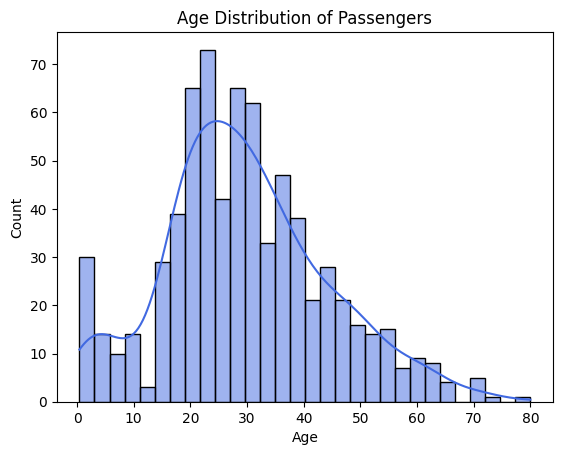

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['Age'].dropna(), bins=30, kde=True, color='royalblue')
plt.title('Age Distribution of Passengers')

Text(0.5, 1.0, 'Ticket Price (Fare) Distribution')

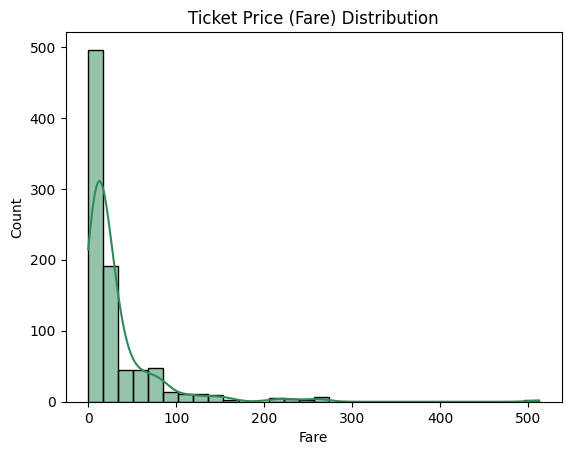

In [7]:
sns.histplot(df['Fare'], bins=30, kde=True, color='seagreen')
plt.title('Ticket Price (Fare) Distribution')

Text(0.5, 1.0, 'Survival Rate: Male vs Female')

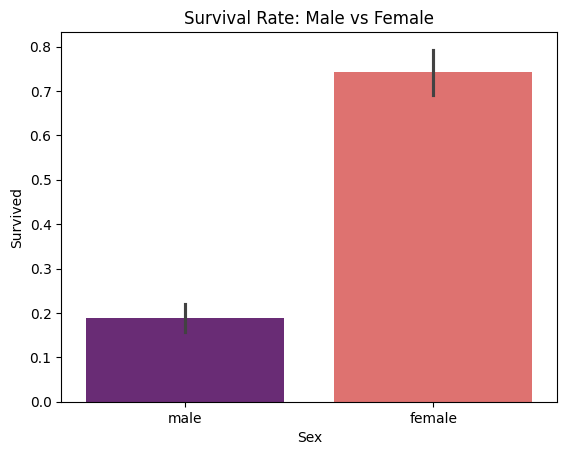

In [38]:
sns.barplot(x='Sex', y='Survived', data=df, hue='Sex', palette='magma')
plt.title('Survival Rate: Male vs Female')

Text(0.5, 1.0, 'Survival Rate: Passenger Class')

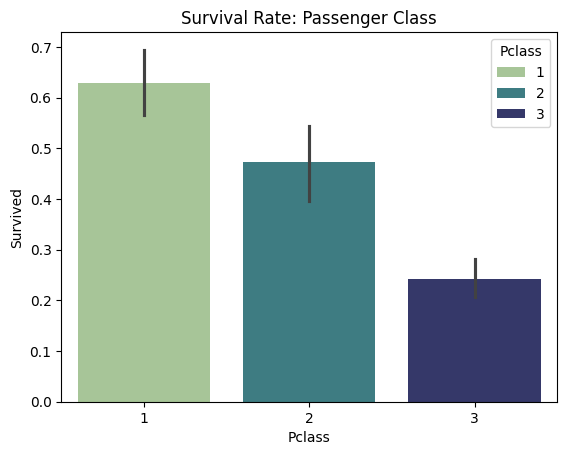

In [50]:
sns.barplot(x='Pclass', y='Survived', data=df, hue='Pclass', palette='crest')
plt.title('Survival Rate: Passenger Class')

Text(0.5, 1.0, 'Boxplot of Pclass vs Age by Survival')

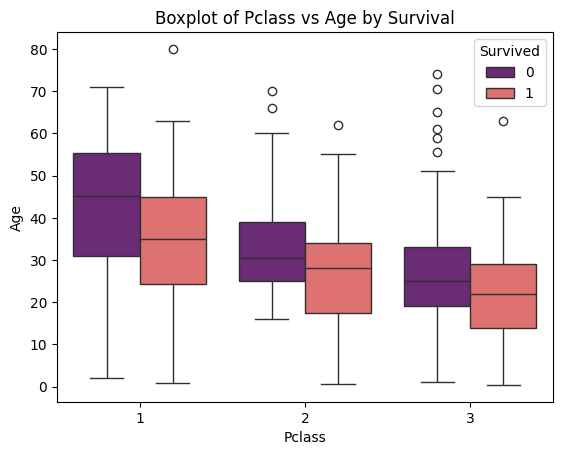

In [48]:
sns.boxplot(data=df, x='Pclass', y='Age', hue='Survived', palette='magma')
plt.title('Boxplot of Pclass vs Age by Survival')


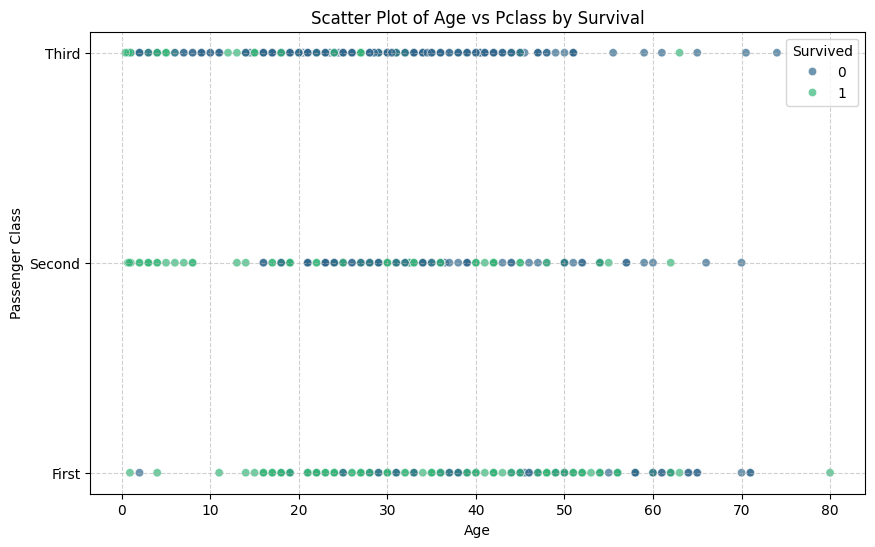

In [47]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Age', y='Pclass', hue='Survived', palette='viridis', alpha=0.7)
plt.title('Scatter Plot of Age vs Pclass by Survival')
plt.xlabel('Age')
plt.ylabel('Passenger Class')
plt.yticks([1, 2, 3], ['First', 'Second', 'Third']) # Make Pclass labels more readable
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Text(0.5, 1.0, 'Feature Correlation Heatmap')

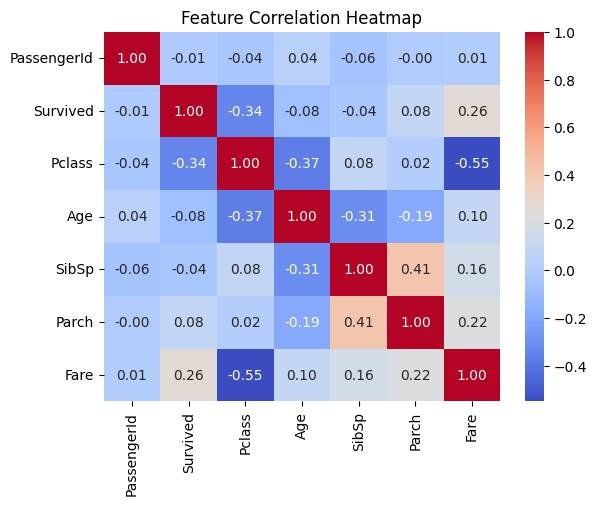

In [51]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')

## Data Preprocessing

In [52]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [57]:
#Fill Age missing values using it's median
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [58]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [93]:
x = df[['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
y = df['Survived']
x.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [118]:
#Split data into train dan validation before encoding and normalization
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
print(x_train.shape)
print(x_val.shape)

(712, 7)
(179, 7)


In [119]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    712 non-null    int64  
 1   Sex       712 non-null    object 
 2   Age       712 non-null    float64
 3   SibSp     712 non-null    int64  
 4   Parch     712 non-null    int64  
 5   Fare      712 non-null    float64
 6   Embarked  712 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 44.5+ KB


In [120]:
x_train['Sex'].value_counts()

,count
Sex,
male,459
female,253


In [121]:
from sklearn.preprocessing import LabelEncoder
label_encoder_sex = LabelEncoder()
x_train['Sex'] = label_encoder_sex.fit_transform(x_train['Sex'])
label_encoder_embarked = LabelEncoder()
x_train['Embarked'] = label_encoder_embarked.fit_transform(x_train['Embarked'])

In [122]:
x_val.info()

<class 'pandas.core.frame.DataFrame'>
Index: 179 entries, 565 to 637
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    179 non-null    int64  
 1   Sex       179 non-null    object 
 2   Age       179 non-null    float64
 3   SibSp     179 non-null    int64  
 4   Parch     179 non-null    int64  
 5   Fare      179 non-null    float64
 6   Embarked  179 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 11.2+ KB


In [123]:
x_val['Sex'].value_counts()

,count
Sex,
male,118
female,61


In [124]:
x_val['Sex'] = label_encoder_sex.transform(x_val['Sex'])
x_val['Embarked'] = label_encoder_embarked.transform(x_val['Embarked'])

In [125]:
x_val.describe()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
count,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000
mean,2.307263,0.659218,28.970670,0.642458,0.346369,33.733145,1.553073
std,0.848331,0.475302,12.989388,1.252228,0.664193,55.843604,0.757901
min,1.000000,0.000000,0.750000,0.000000,0.000000,0.000000,0.000000
25%,1.500000,0.000000,24.000000,0.000000,0.000000,7.987500,1.000000
50%,3.000000,1.000000,28.000000,0.000000,0.000000,15.245800,2.000000
75%,3.000000,1.000000,33.000000,1.000000,0.000000,31.797900,2.000000
max,3.000000,1.000000,70.000000,8.000000,2.000000,512.329200,2.000000


In [126]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_train = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
display(x_train.head())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
692,1.0,1.0,0.346569,0.000,0.000000,0.110272,1.0
481,0.5,1.0,0.346569,0.000,0.000000,0.000000,1.0
527,0.0,1.0,0.346569,0.000,0.000000,0.432884,1.0
855,1.0,0.0,0.220910,0.000,0.166667,0.018250,1.0
801,0.5,0.0,0.384267,0.125,0.166667,0.051237,1.0


In [127]:
x_val_scaled = scaler.transform(x_val)
x_val = pd.DataFrame(x_val_scaled, columns=x_val.columns, index=x_val.index)
x_val.describe()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
count,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000
mean,0.653631,0.659218,0.358767,0.080307,0.057728,0.065843,0.776536
std,0.424166,0.475302,0.163224,0.156528,0.110699,0.108999,0.378951
min,0.000000,0.000000,0.004147,0.000000,0.000000,0.000000,0.000000
25%,0.250000,0.000000,0.296306,0.000000,0.000000,0.015591,0.500000
50%,1.000000,1.000000,0.346569,0.000000,0.000000,0.029758,1.000000
75%,1.000000,1.000000,0.409399,0.125000,0.000000,0.062065,1.000000
max,1.000000,1.000000,0.874340,1.000000,0.333333,1.000000,1.000000
